# 3. Customer value, expected value and targeting

**Goal.** Turn probabilities into a decision: a customer value proxy, the expected net value of each offer, and the list that maximises total expected value within a fixed budget, compared with simple rules such as "highest churn risk only".

Numbers in the text were generated for run `20261010T155849068129Z-88be4b93`.

In [1]:
import pandas as pd
from IPython.display import display, Image
from telco_retention.common import ROOT, latest_run, read_json
from telco_retention.business import campaign, default_offer, value_customers, offer_options
from telco_retention.analysis import campaign_budget, run_strategy
pd.set_option("display.precision", 3)
run = latest_run()
cfg = read_json(run / "manifest.json")["config"]
scores = pd.read_csv(run / "scorecard.csv").query("split == 'test'")
thresholds = read_json(run / "targeting_thresholds.json")
budget = campaign_budget(len(scores), cfg)
print("Run:", run.name, "| test customers:", len(scores), "| budget:", budget)

Run: 20261010T155849068129Z-88be4b93 | test customers: 1409 | budget: 3500.0


## Value proxy and expected value, by hand

Value = monthly charges x margin (30%) x discounted months (base 12 months x tenure factor, 10% a year). EV = p x save rate x value - (offer cost + contact cost). The cell recomputes three customers by hand and compares with the package.

In [2]:
offer = default_offer(cfg)
valued = value_customers(scores.head(3), cfg)
options = offer_options(valued, [offer])
hand = valued.assign(ev_by_hand=valued.churn_probability * offer["save_rate"] * valued.customer_value - (offer["offer_cost"] + offer["contact_cost"]))
display(hand[["customer_id", "MonthlyCharges", "tenure", "tenure_segment", "discounted_months", "customer_value", "churn_probability", "ev_by_hand"]])
assert (hand.ev_by_hand.round(9).values == options.expected_net_value.round(9).values).all()

,customer_id,MonthlyCharges,tenure,tenure_segment,discounted_months,customer_value,churn_probability,ev_by_hand
0,1452-KIOVK,89.10,22,developing,11.400,304.735,0.474,3.863
1,6713-OKOMC,29.75,10,new,8.651,77.214,0.287,-20.562
2,6388-TABGU,56.15,62,loyal,14.085,237.259,0.016,-24.262


## Same budget, different rules

,strategy,selected_count,cost,expected_net_value,roi,precision_contacted,high_risk_high_value_coverage,label_based_simulated_net
0,none,0.0,0.0,0.000,NaN,NaN,0.000,0.000
1,risk,140.0,3500.0,1300.589,0.372,0.707,0.123,1078.884
2,risk_positive_ev,140.0,3500.0,1366.586,0.390,0.693,0.123,1105.020
3,value,140.0,3500.0,-1037.491,-0.296,0.286,0.298,89.901
4,ev,140.0,3500.0,2340.018,0.669,0.600,0.965,1977.062
5,segment_offers,153.0,3500.0,2668.203,0.762,0.601,0.982,2155.698
6,random_mean,140.0,3500.0,-1644.518,-0.470,0.262,0.102,-1688.310


,strategy,label_based_simulated_net,lower_95,upper_95
0,none,0.000,0.000,0.000
1,risk,1078.884,517.254,1668.844
2,risk_positive_ev,1105.020,544.869,1698.698
3,value,89.901,-785.682,1070.742
4,ev,1977.062,1109.219,2853.774
5,segment_offers,2155.698,1192.512,3176.386
6,ev minus risk,898.178,107.058,1744.264
7,ev minus risk_positive_ev,872.042,71.451,1736.238
8,segment_offers minus ev,178.636,-153.217,577.099
9,segment_offers minus risk,1076.814,228.798,2001.825


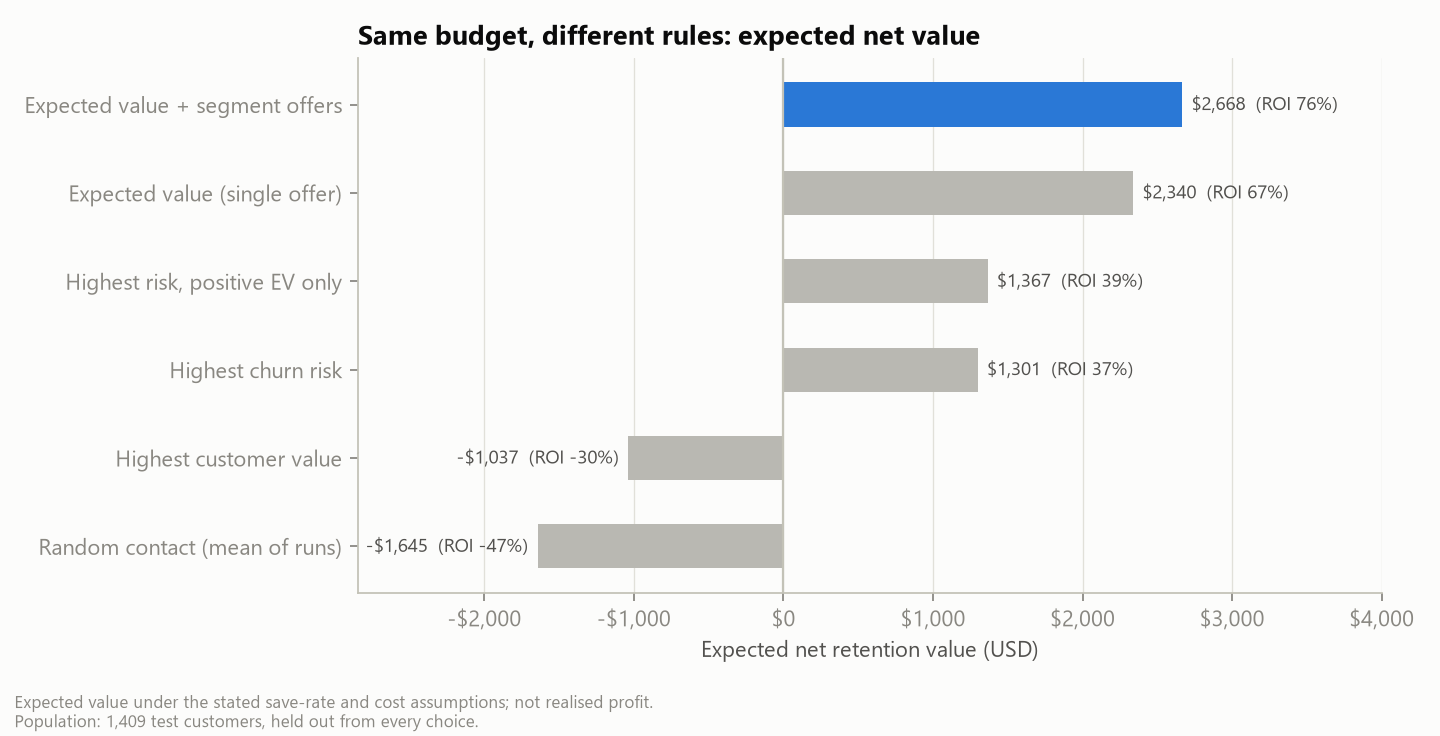

In [3]:
comparison = pd.read_csv(run / "strategy_comparison.csv")
display(comparison[["strategy", "selected_count", "cost", "expected_net_value", "roi", "precision_contacted", "high_risk_high_value_coverage", "label_based_simulated_net"]])
display(pd.read_csv(run / "economic_uncertainty.csv")[["strategy", "label_based_simulated_net", "lower_95", "upper_95"]])
display(Image(filename=str(ROOT / "reports/figures/strategy_comparison.png")))

**Interpretation.** With $3,500, risk-only targeting has an expected net value of $1,301 and expected-value targeting with the standard offer $2,340 (+$1,039). Checked against actual outcomes (paired bootstrap), the targeting gain is $898 with a 95% interval of $107 to $1,744. Risk-only has higher precision (71%) but reaches only 12% of high-risk, high-value customers.

## Segment-specific offers

In [4]:
display(pd.read_csv(run / "offer_catalog.csv"))
decisions = read_json(run / "validation_decisions.json")
display(pd.DataFrame(decisions["strategy_selection"]["validation"]).T[["selected_count", "cost", "expected_net_value", "roi"]])
print("Chosen on validation:", decisions["strategy_selection"]["strategy"], "| relative gain:", round(decisions["strategy_selection"]["relative_gain"], 3))
display(pd.read_csv(run / "segment_offer_mix.csv"))

,offer_id,label,offer_cost,contact_cost,save_rate,eligibility
0,standard,One-time $20 bill credit,20.0,5.0,0.20,All customers
1,contract_upgrade,$35 credit for moving to a 1-year contract,35.0,5.0,0.30,Contract: Month-to-month
2,service_bundle,6 months free TechSupport + OnlineSecurity,12.0,5.0,0.15,InternetService: DSL or Fiber optic; TechSuppo...
3,loyalty_reward,$10 loyalty reward,10.0,5.0,0.10,tenure_segment: loyal


,selected_count,cost,expected_net_value,roi
ev,140,3500.0,2342.294,0.669
segment_offers,152,3499.0,2651.004,0.758


Chosen on validation: segment_offers | relative gain: 0.132


,tenure_segment,Contract,offer_id,customers
0,new,Month-to-month,contract_upgrade,1
1,new,Month-to-month,service_bundle,39
2,new,Month-to-month,standard,2
3,developing,Month-to-month,contract_upgrade,10
4,developing,Month-to-month,service_bundle,28
5,developing,Month-to-month,standard,1
6,loyal,Month-to-month,contract_upgrade,26
7,loyal,Month-to-month,service_bundle,43
8,loyal,Month-to-month,standard,3


**Interpretation.** The optimiser (a knapsack solved exactly with HiGHS) chooses at most one eligible offer per customer. On validation, segment offers beat the single offer by 13%, so the recommended rule is **expected value + segment offers**. On test the extra expected value is $328; with actual outcomes it is $179, i.e. not distinguishable from zero. The offer-design gain rests on assumed save rates and must be tested.

## Who gets contacted

,quadrant,customers,customer_share,observed_churn,mean_probability,mean_customer_value,value_at_risk,value_at_risk_share,selected_risk,selected_ev,selected_segment_offers
0,High risk / High value,57,0.040,0.544,0.562,402.375,12879.149,0.137,7,55,56
1,High risk / Low value,306,0.217,0.598,0.635,220.938,43215.178,0.461,133,79,85
2,Low risk / High value,291,0.207,0.192,0.164,414.306,19608.868,0.209,0,6,12
3,Low risk / Low value,755,0.536,0.138,0.141,163.570,18016.995,0.192,0,0,0


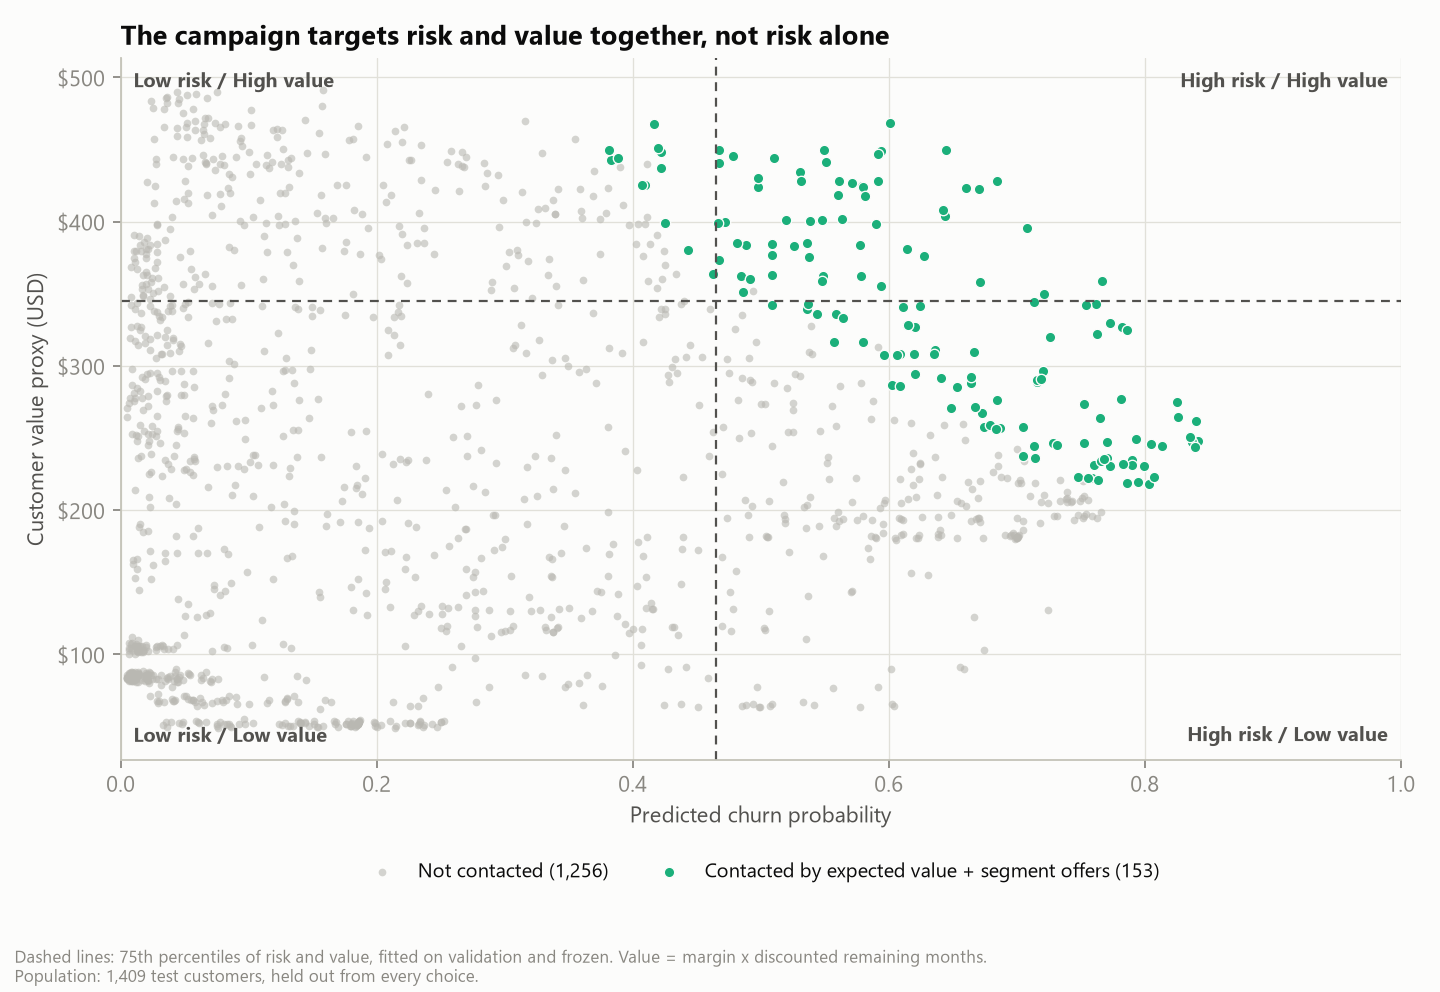

Scenario e0347326ca4d | matches the report: True


,customer_id,churn_probability,customer_value,offer_id,expected_net_value,decision_detail
403,2809-ZMYOQ,0.685,428.249,contract_upgrade,47.971,p=68.5% x save rate 30% x value 428.25 - cost ...
771,5380-WJKOV,0.645,449.377,contract_upgrade,46.908,p=64.5% x save rate 30% x value 449.38 - cost ...
1171,8397-MVTAZ,0.670,422.756,contract_upgrade,45.027,p=67.0% x save rate 30% x value 422.76 - cost ...
853,6030-REHUX,0.601,468.391,contract_upgrade,44.480,p=60.1% x save rate 30% x value 468.39 - cost ...
1031,7402-EYFXX,0.708,395.502,contract_upgrade,44.005,p=70.8% x save rate 30% x value 395.50 - cost ...
687,4817-VYYWS,0.660,423.390,contract_upgrade,43.846,p=66.0% x save rate 30% x value 423.39 - cost ...
1285,9221-OTIVJ,0.767,358.602,contract_upgrade,42.469,p=76.7% x save rate 30% x value 358.60 - cost ...
44,0337-CNPZE,0.594,449.165,contract_upgrade,40.056,p=59.4% x save rate 30% x value 449.17 - cost ...
166,1104-TNLZA,0.591,447.053,contract_upgrade,39.311,p=59.1% x save rate 30% x value 447.05 - cost ...
964,6899-PPEEA,0.642,407.967,contract_upgrade,38.597,p=64.2% x save rate 30% x value 407.97 - cost ...


In [5]:
display(pd.read_csv(run / "risk_value_matrix.csv"))
display(Image(filename=str(ROOT / "reports/figures/risk_value.png")))
target, summary = run_strategy(scores, budget, cfg, decisions["strategy_selection"]["strategy"], thresholds)
print("Scenario", summary["scenario_id"], "| matches the report:", summary["scenario_id"] == read_json(run / "campaign_scenarios.json")[decisions["strategy_selection"]["strategy"]]["scenario_id"])
display(target.loc[target.selected].nlargest(10, "expected_net_value")[["customer_id", "churn_probability", "customer_value", "offer_id", "expected_net_value", "decision_detail"]])

## Who the recommended list contacts

,attribute,group,list_share,not_contacted_share,all_share
0,Contract,Month-to-month,0.969,0.435,0.558
1,Contract,One year,0.031,0.253,0.202
2,Contract,Two year,0.000,0.312,0.241
3,InternetService,DSL,0.003,0.443,0.342
4,InternetService,Fiber optic,0.997,0.277,0.443
5,InternetService,No,0.000,0.279,0.215
6,PaymentMethod,Bank transfer (automatic),0.102,0.249,0.215
7,PaymentMethod,Credit card (automatic),0.130,0.244,0.218
8,PaymentMethod,Electronic check,0.725,0.239,0.351
9,PaymentMethod,Mailed check,0.043,0.268,0.216


{'list': {'customers': 324,
  'median_monthly_charges': 89.32499999999999,
  'mean_tenure': 20.01851851851852,
  'mean_probability': 0.5987633378055841,
  'mean_customer_value': 304.66485857557336},
 'not_contacted': {'customers': 1085,
  'median_monthly_charges': 56.1,
  'mean_tenure': 36.18617511520738,
  'mean_probability': 0.17161379946886451,
  'mean_customer_value': 217.40921165718024},
 'all': {'customers': 1409,
  'median_monthly_charges': 70.35,
  'mean_tenure': 32.46841731724627,
  'mean_probability': 0.26983697223046643,
  'mean_customer_value': 237.4736755333757}}

,offer_id,customers,cost,mean_probability,mean_customer_value
0,contract_upgrade,150,6000.0,0.63,338.42
1,service_bundle,150,2550.0,0.59,266.81
2,standard,24,600.0,0.49,330.26


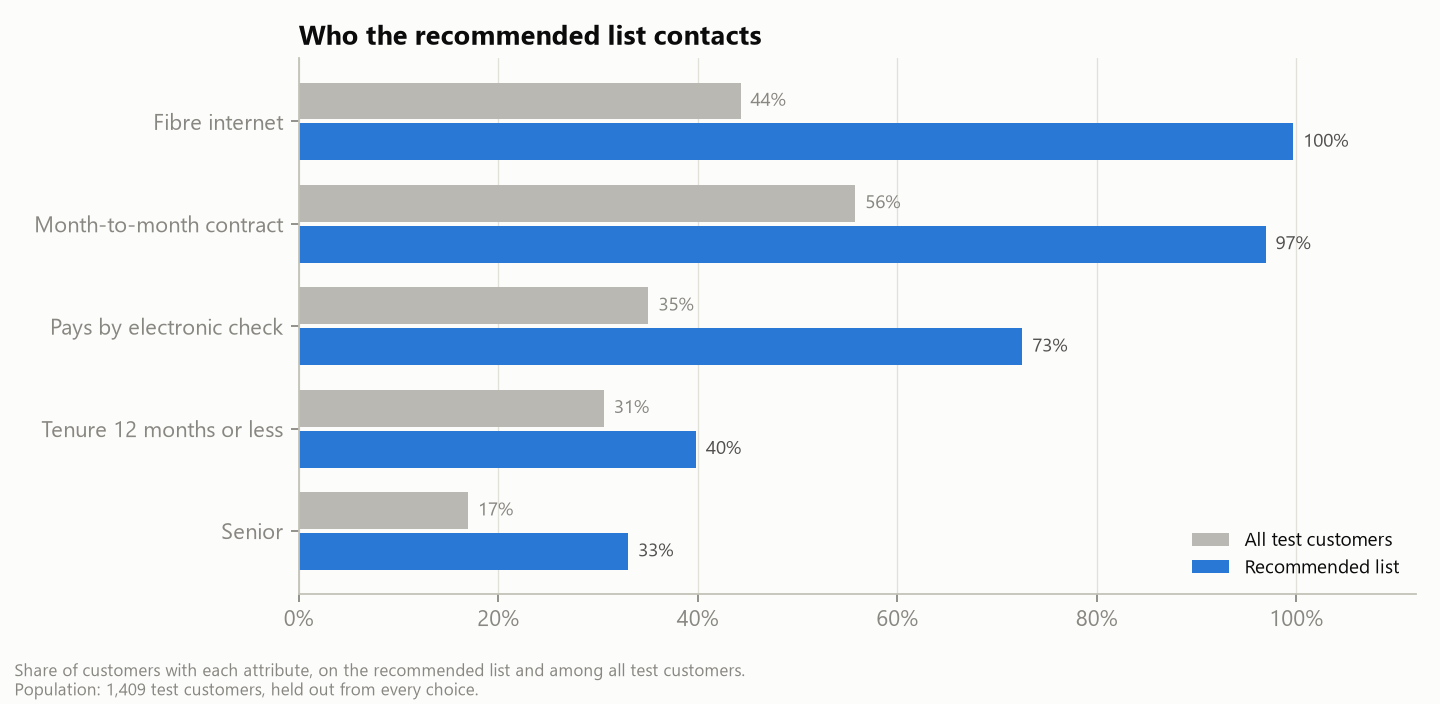

In [6]:
display(pd.read_csv(run / "target_profile.csv").round(3))
display(read_json(run / "target_profile_summary.json"))
display(pd.read_csv(run / "recommended_offer_mix.csv").round(2))
display(Image(filename=str(ROOT / "reports/figures/target_profile.png")))

**Interpretation.** The recommended list is 100% fibre and 97% month-to-month, with a median bill of $89 against $70 for all test customers. Low-risk customers and risky customers with small bills are left out. Because the campaign rides on one segment, the pilot reports fibre and month-to-month customers separately.

**So what.** The customer-level targeting tables (`reports/tables/targeting_recommended.csv` and `targeting_segment_offers.csv`) and the churn scorecard (`reports/tables/scorecard.csv`, plus the [points card](../docs/churn-scorecard.md)) are the operational deliverables; every row carries its formula and scenario ID.